![Baseball Flights](baseball_flights.png)


To the Office of Transportation at The 22nd Century Sporting League,

After our inaugural 2101 season, The League is looking for ways to optimize our game scheduling process and costs.  We know that transportation logistics are a major variable to consider during scheduling, and as such, we’ve got a few questions for you. 

Our primary areas of focus are surrounding the number of jets that The League needs to own, and the cost of fuel for those flights. If we want The League to enjoy continued success, we'll need to make sure we manage transportation costs.

We’re sharing schedule data for the upcoming 2102 season.  On each row, you’ll find information about which teams are needing to travel to their next set of games, the time the flight will likely depart (based on our estimations of gameplay durations) and the time the flight will likely land. 

Additionally, we're also providing the fuel price that was paid each day during this past 2101 season. The fuel price fluctuates over time, but we're hoping you'll be able to project it to the future to help with the analysis.

## The Data

### team_flights.csv

| Column     | Description              |
|------------|--------------------------|
| `team_name` | Official team name |
| `departure_datetime` | Date and Time (in UTC) when the flight will depart |
| `landing_datetime` | Date and Time (in UTC) when the flight will land |


### fuel_price.csv

| Column     | Description              |
|------------|--------------------------|
| `date` | Date when the fuel price was recorded |
| `fuel_price` | Corresponding fuel price (in $ per gallon) |


### Important Things to Know
- You can assume that the flight's average speed is 500 MPH. (So, as an example, a 2-hour flight would travel 1000 miles)
- You can assume that each team’s jet fills up with fuel equivalent to 1 gallon per mile-of-travel 
- You can assume that the jet is fueled on the day the travel departs (and thus can use the fuel price corresponding to the departure date)

In [510]:
# Import required modules
import pandas as pd
import numpy as np
from statsmodels.tsa.statespace.sarimax import SARIMAX
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf  
from statsmodels.tsa.stattools import adfuller
from pmdarima.arima import auto_arima
# Explore the data
team_flights = pd.read_csv('./team_flights.csv')
fuel_prices = pd.read_csv('./fuel_prices_2101.csv',
                         index_col='date')

team_flights.head()

# Some basic data cleaning and pre-processing
team_flights['departure_datetime'] = pd.to_datetime(team_flights['departure_datetime'])
team_flights['landing_datetime']   = pd.to_datetime(team_flights['landing_datetime'])

fuel_prices.index = pd.DatetimeIndex(fuel_prices.index).to_period('D')

In [511]:
team_flights

,team_name,departure_datetime,landing_datetime,travel_distance_miles
0,Agile Antelopes,2102-04-06 21:37:00,2102-04-07 00:35:57,1491.250000
1,Agile Antelopes,2102-04-10 23:57:00,2102-04-11 01:35:40,822.222222
2,Agile Antelopes,2102-04-14 00:29:00,2102-04-14 05:02:55,2282.638889
3,Agile Antelopes,2102-04-21 03:31:00,2102-04-21 05:23:09,934.583333
4,Agile Antelopes,2102-04-24 22:23:00,2102-04-25 00:25:50,1023.611111
...,...,...,...,...
1140,Diligent Data Scientists,2102-09-05 01:22:00,2102-09-05 03:14:19,935.972222
1141,Diligent Data Scientists,2102-09-07 23:56:00,2102-09-08 04:26:26,2253.611111
1142,Diligent Data Scientists,2102-09-18 22:20:00,2102-09-18 23:00:50,340.277778
1143,Diligent Data Scientists,2102-09-23 03:37:00,2102-09-23 05:40:32,1029.444444


In [512]:
fuel_prices

,price
date,
2101-01-01,0.97
2101-01-02,0.87
2101-01-03,0.87
2101-01-04,0.97
2101-01-05,1.10
...,...
2101-12-27,1.33
2101-12-28,1.46
2101-12-29,1.51


In [513]:
# Q1) Find the Max teams simultaneously in flight
# How? A cumulative sum of (departed flights - flights that have landed ) over time 

# Two new Dataframes, one for Departures and one for Arrivals -  Departures are given a value of 1, Arrivals are given a value of -1 - Concatenate then find the cumulative sum of 1/-1 sorted over time 

# Departures Dataframe 
departures = team_flights['departure_datetime'].rename('time').to_frame()
departures['value'] = 1
print(departures.head(5))

# Arrivals Dataframe
arrivals = team_flights['landing_datetime'].rename('time').to_frame()
arrivals['value'] = -1
print(arrivals.head(5))

# Concatenate the two dataframes and sort by time, then value
n_in_flight = pd.concat([departures, arrivals]).sort_values(['time', 'value'])

# Create the cumulative sum
n_in_flight['cumsum'] = n_in_flight['value'].cumsum()
print(n_in_flight.head(20))
print(n_in_flight['cumsum'].max())

                 time  value
0 2102-04-06 21:37:00      1
1 2102-04-10 23:57:00      1
2 2102-04-14 00:29:00      1
3 2102-04-21 03:31:00      1
4 2102-04-24 22:23:00      1
                 time  value
0 2102-04-07 00:35:57     -1
1 2102-04-11 01:35:40     -1
2 2102-04-14 05:02:55     -1
3 2102-04-21 05:23:09     -1
4 2102-04-25 00:25:50     -1
                    time  value  cumsum
153  2102-04-03 21:40:00      1       1
649  2102-04-03 21:40:00      1       2
725  2102-04-03 21:52:00      1       3
1031 2102-04-03 22:02:00      1       4
992  2102-04-03 22:04:00      1       5
840  2102-04-03 22:19:00      1       6
802  2102-04-03 22:20:00      1       7
1108 2102-04-03 22:44:00      1       8
954  2102-04-03 22:45:00      1       9
1108 2102-04-03 23:11:55     -1       8
649  2102-04-03 23:13:44     -1       7
610  2102-04-03 23:16:00      1       8
115  2102-04-03 23:17:00      1       9
572  2102-04-03 23:17:00      1      10
725  2102-04-03 23:17:13     -1       9
153  2102-04

19


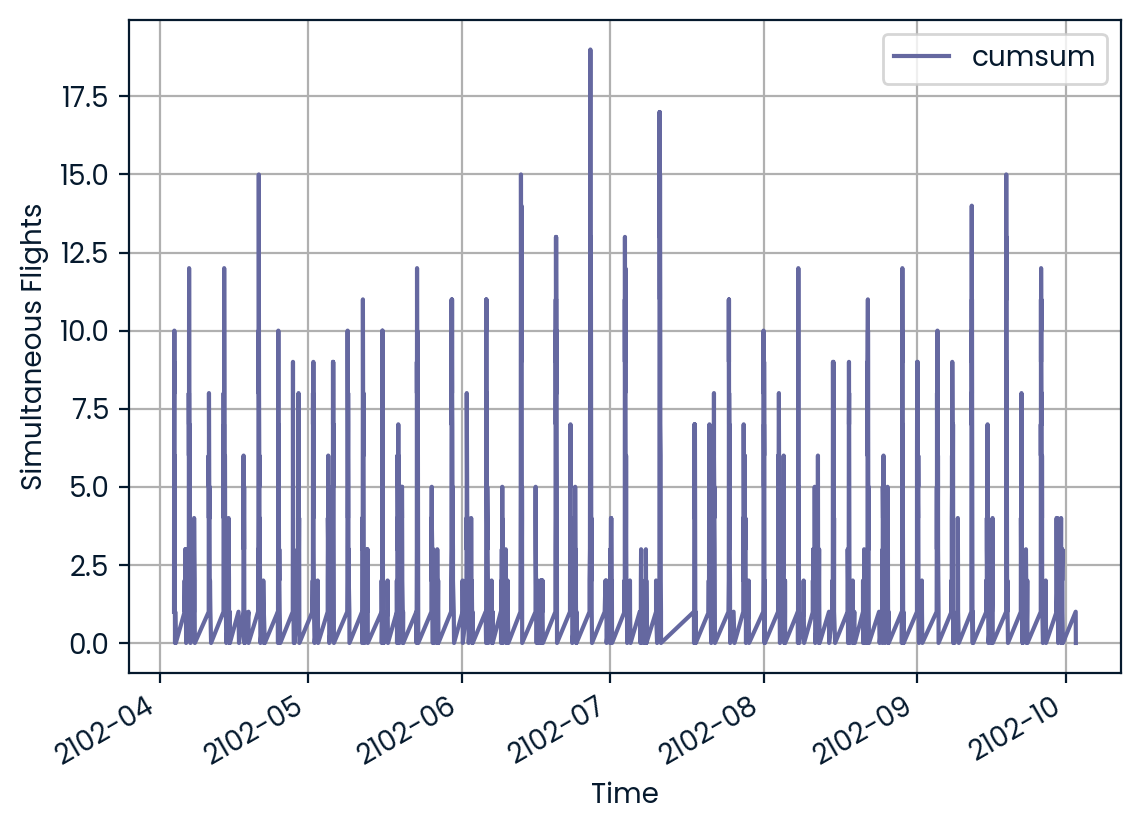

In [514]:
# Now to plot the data and find the maximum simultaneous flights!
n_in_flight.plot(x='time', y='cumsum', kind='line', grid=True, ylabel='Simultaneous Flights', xlabel='Time')
print(n_in_flight['cumsum'].max())
max_teams_in_flight = n_in_flight['cumsum'].max().astype('float')

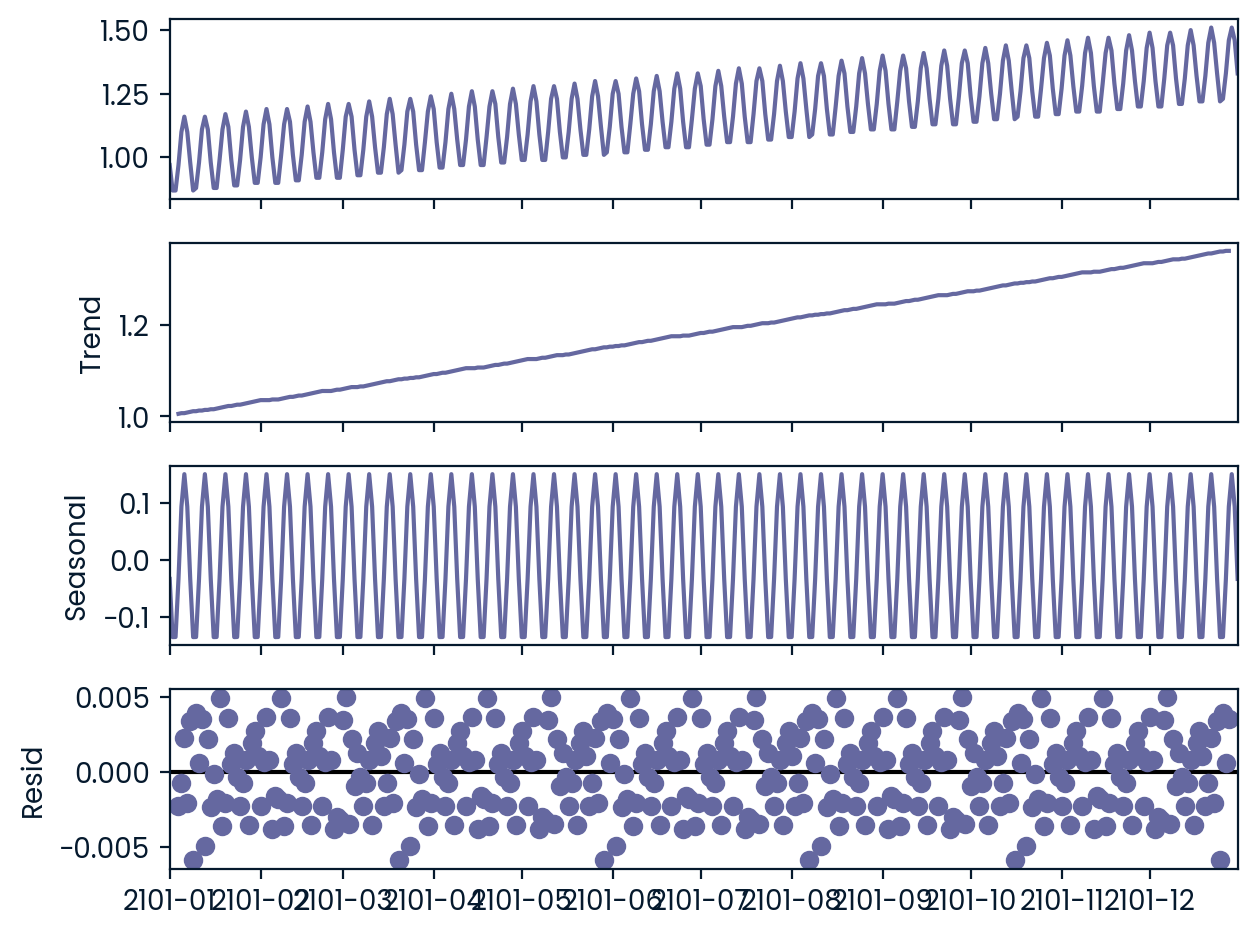

In [515]:
# Q2) Predict the Fuel spend for the 2102 season 
# How? Use a SARIMA model to predict fuel prices for the 2102 season, then using the using the distance travelled and MPG information we have find the fuel cost per flight when can then be totalled 

# Lets run a seasonal decompose to inspect the data 
fuel_prices.index = fuel_prices.index.to_timestamp()
decomp = seasonal_decompose(fuel_prices)
decomp.plot()
plt.show()

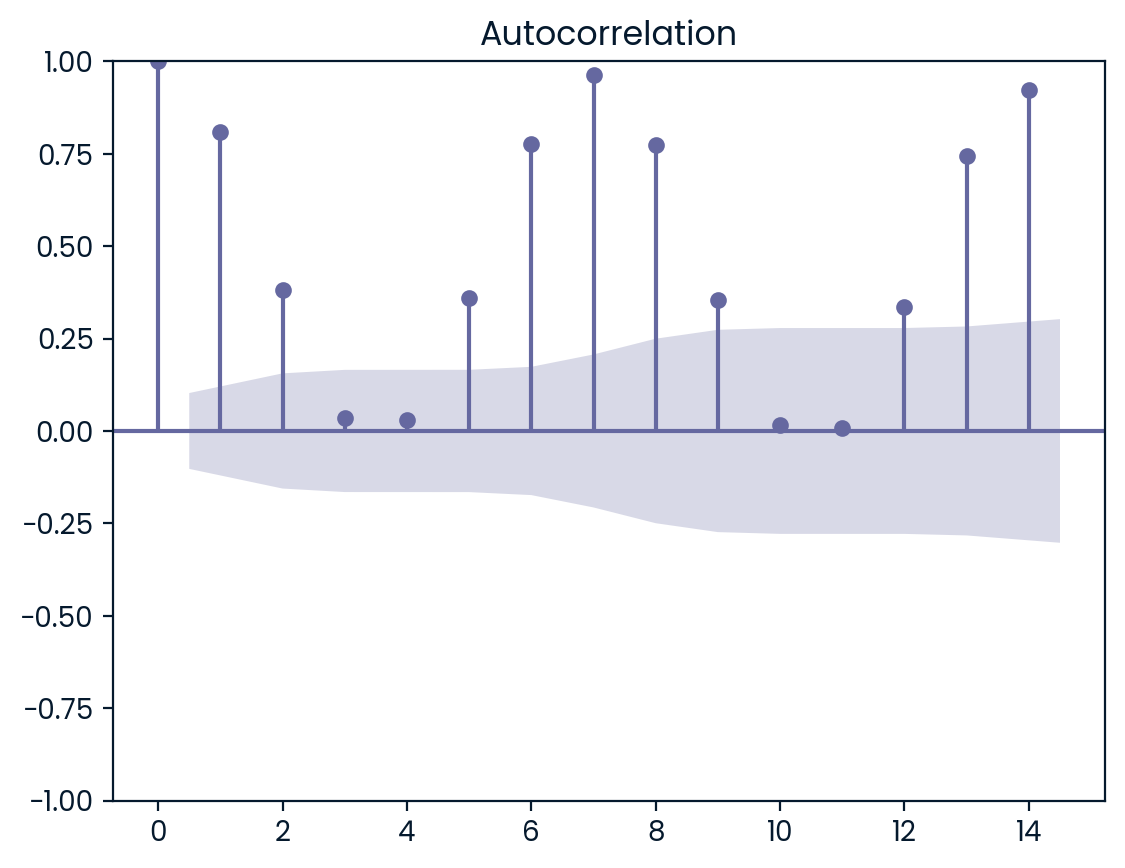

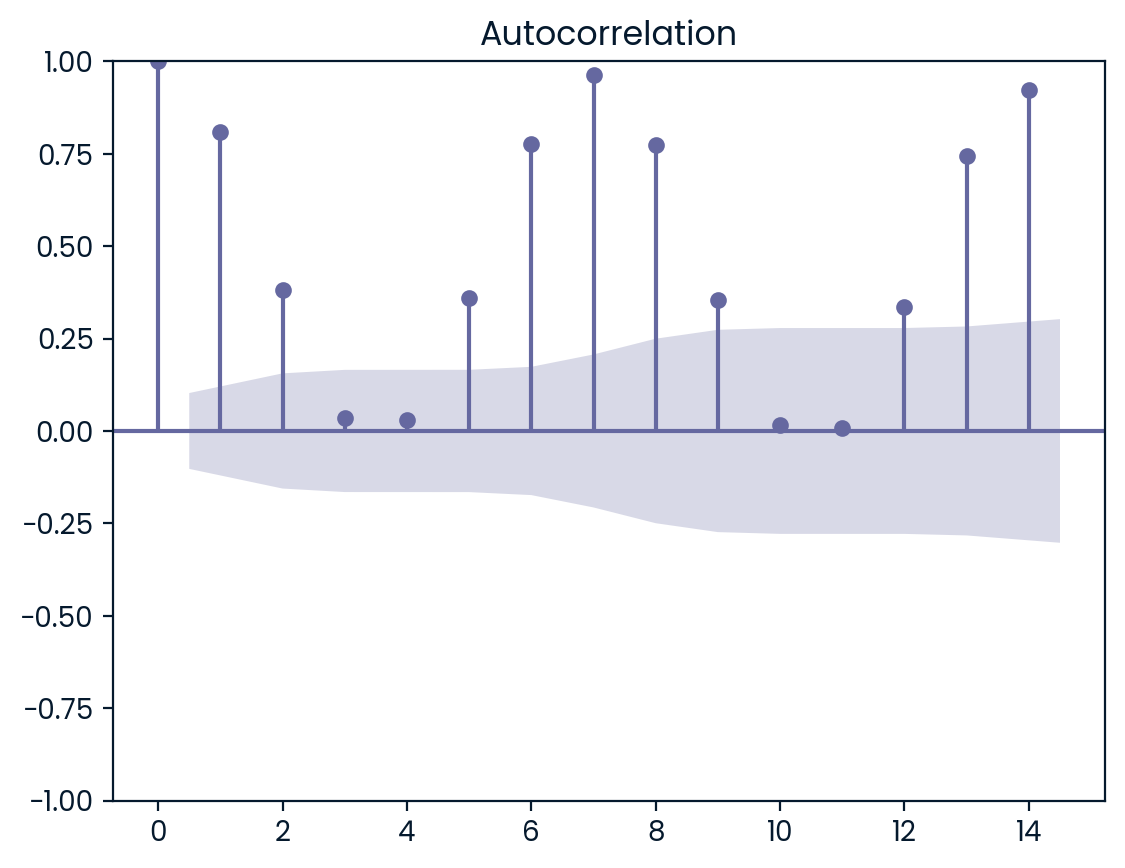

In [516]:
# We can plot the Autocorrelation Function to find the seasonality of the data - We know the data is daily so would assume that seasonality is a period of 7 days, which is confirmed by the AFC.
plot_acf(fuel_prices['price'], lags=14)

If the p-value 0.9664205149823116 > 0.05 then the series is non-stationary
If the p-value 1.048987822874583e-08 > 0.05 then the series is non-stationary for the differenced time series


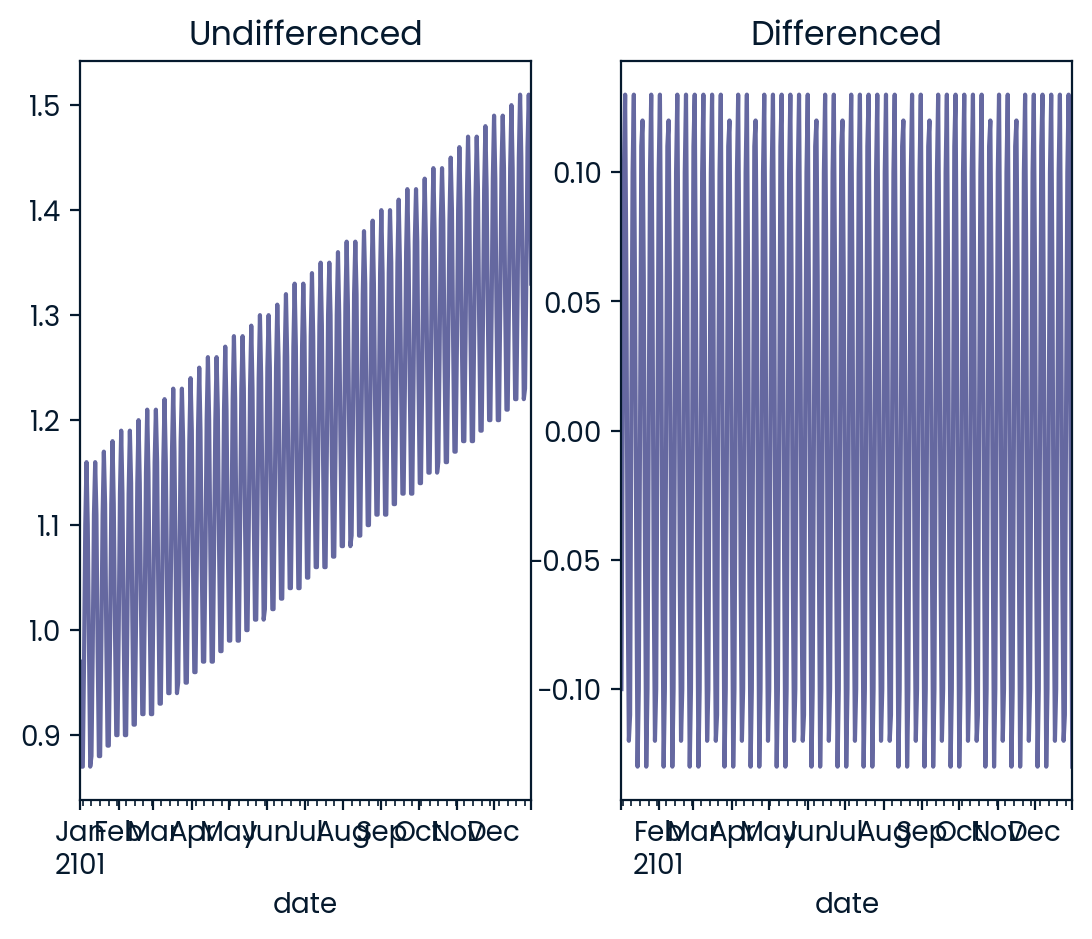

In [517]:
# Before we can create the SARIMA model we must make sure that the time series is stationary - we can test this use the Augmented Dicky Fuller test 

fig, (ax1, ax2) = plt.subplots(1,2)

# A visual check of the series - the mean and variance should both be constant 
fuel_prices['price'].plot(ax=ax1, title='Undifferenced')
result = adfuller(fuel_prices['price'])
print('If the p-value',result[1],'> 0.05 then the series is non-stationary')

# Because the raw time series was found to be non-Stationary using the ADF test we will differnce the time series 
fuel_prices['diff'] = fuel_prices['price'].diff(1)
fuel_prices.dropna(inplace=True)                          # Drop the NaN value created
fuel_prices['diff'].plot(ax=ax2, title='Differenced')
result_diff = adfuller(fuel_prices['diff'])
print('If the p-value',result_diff[1],'> 0.05 then the series is non-stationary for the differenced time series')

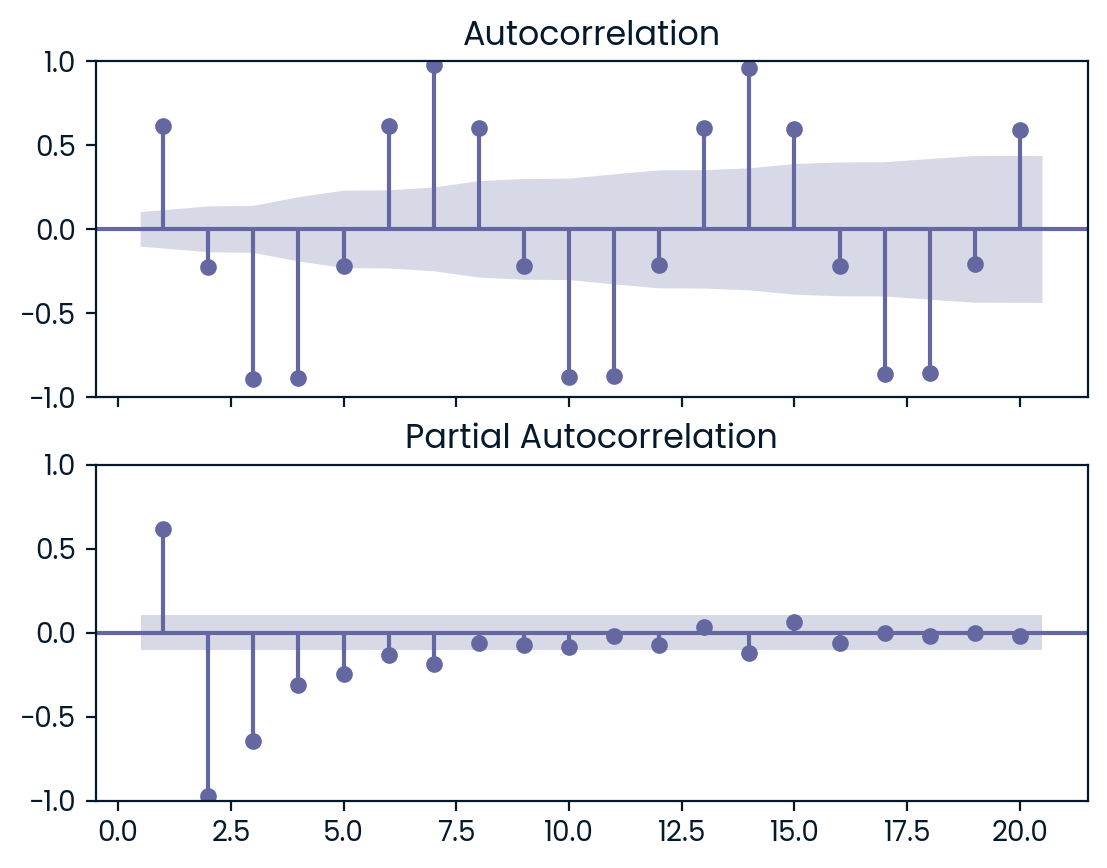

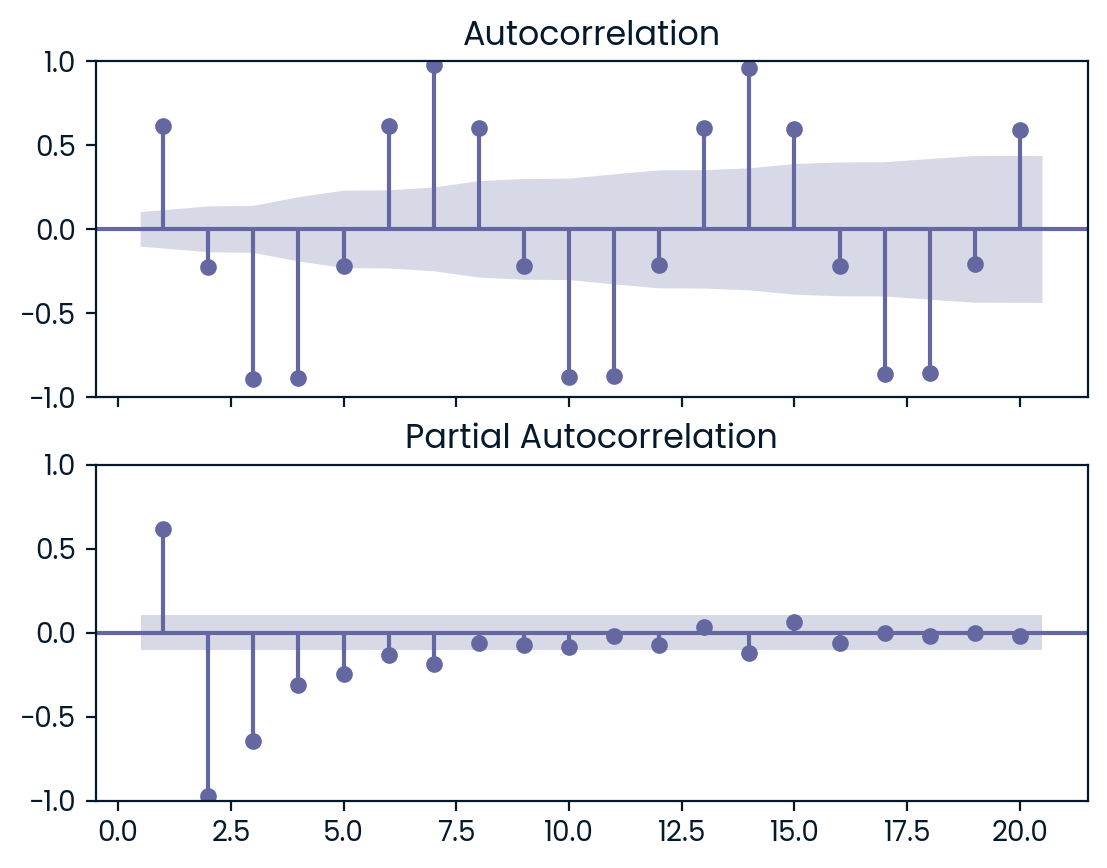

In [518]:
# Now we must use the ACF and PACF to find the orders of the Seasonal and non-Seasonal components of the time series
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
plot_acf(fuel_prices['diff'], ax=ax1, zero=False, lags=20)          # Totally inconspicuous and non-artifical time series
plot_pacf(fuel_prices['diff'], ax=ax2, zero=False, lags=20)
# Possibly a 3/4th order AR model

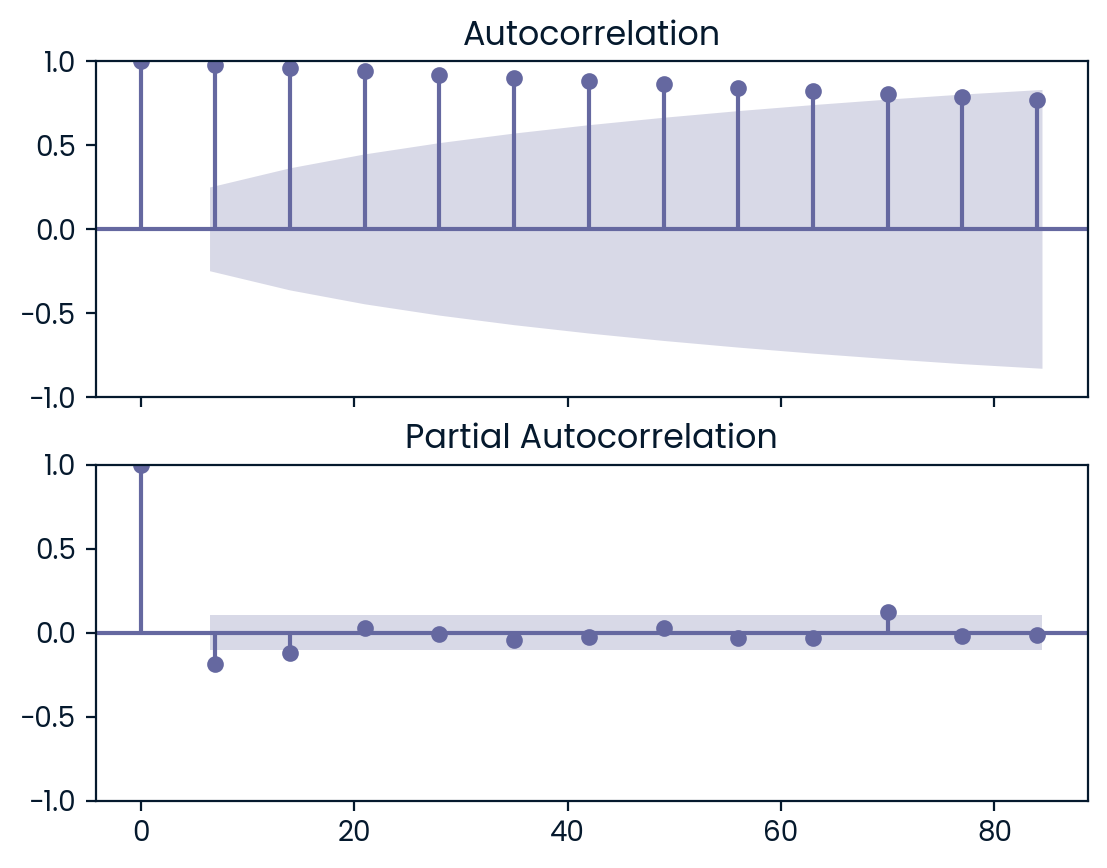

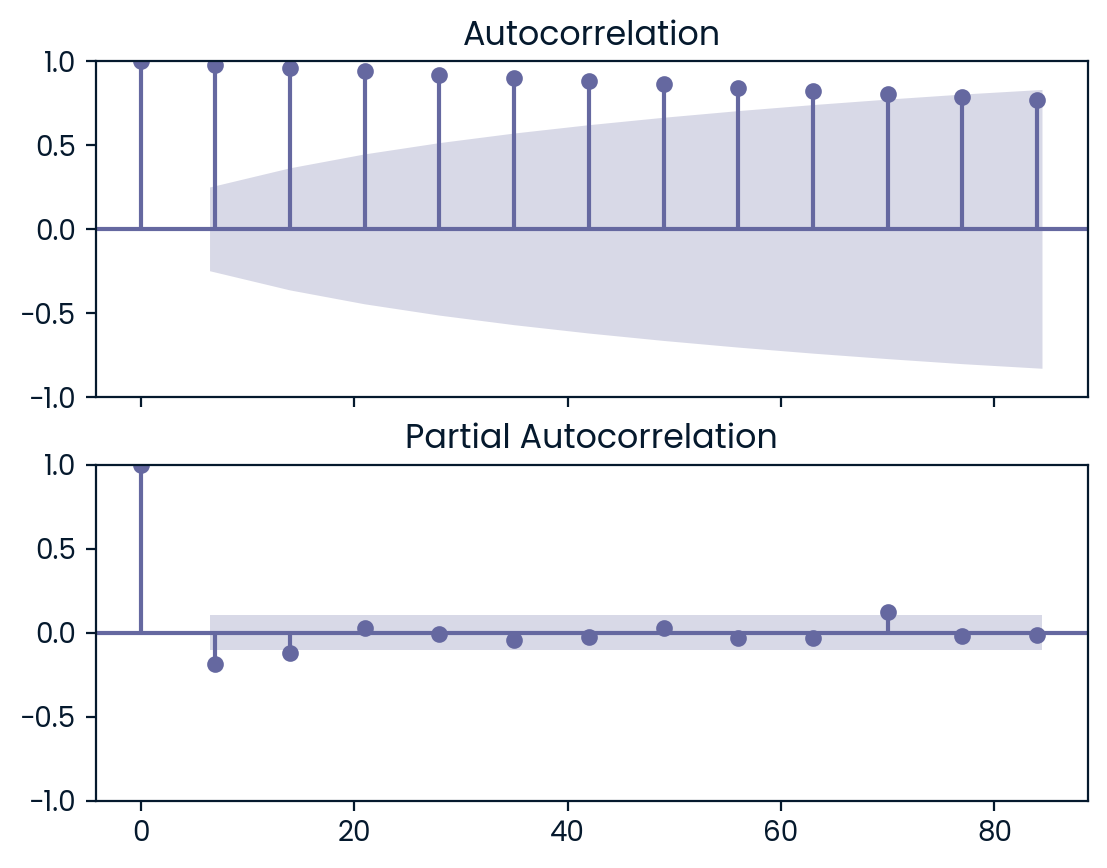

In [519]:
lags = [i * 7 for i in range(13)]
fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True)
plot_acf(fuel_prices['diff'], ax=ax1, zero=False, lags=lags)       # Totally inconspicuous and non-artifical time series
plot_pacf(fuel_prices['diff'], ax=ax2, zero=False, lags=lags)
# Fortunately this one is easy and we have an AR(1) pattern

In [520]:
fuel_prices = fuel_prices.drop('diff', axis=1)
model = SARIMAX(fuel_prices, order=(1,1,1), seasonal_order=(1,0,0,7))
results = model.fit()
print(results.summary())

 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            4     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f= -1.64286D+00    |proj g|=  1.35801D+01

At iterate    5    f= -3.31783D+00    |proj g|=  7.13415D+00

At iterate   10    f= -3.50241D+00    |proj g|=  1.17315D+02

At iterate   15    f= -3.84151D+00    |proj g|=  9.79139D-01

At iterate   20    f= -3.84938D+00    |proj g|=  1.97655D+01

At iterate   25    f= -3.87137D+00    |proj g|=  5.99985D-01

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy searches
Skip  = number of BFGS updates skipped
Nact  = number of active bounds at final generalized Cauchy point
Projg = norm of the final projected gradient
F     = final function value

           * * *

   N    Tit     Tnf  Tnint  Skip  Nact     Projg        F
    4     29     45      1     0     0   

<AxesSubplot: xlabel='date'>

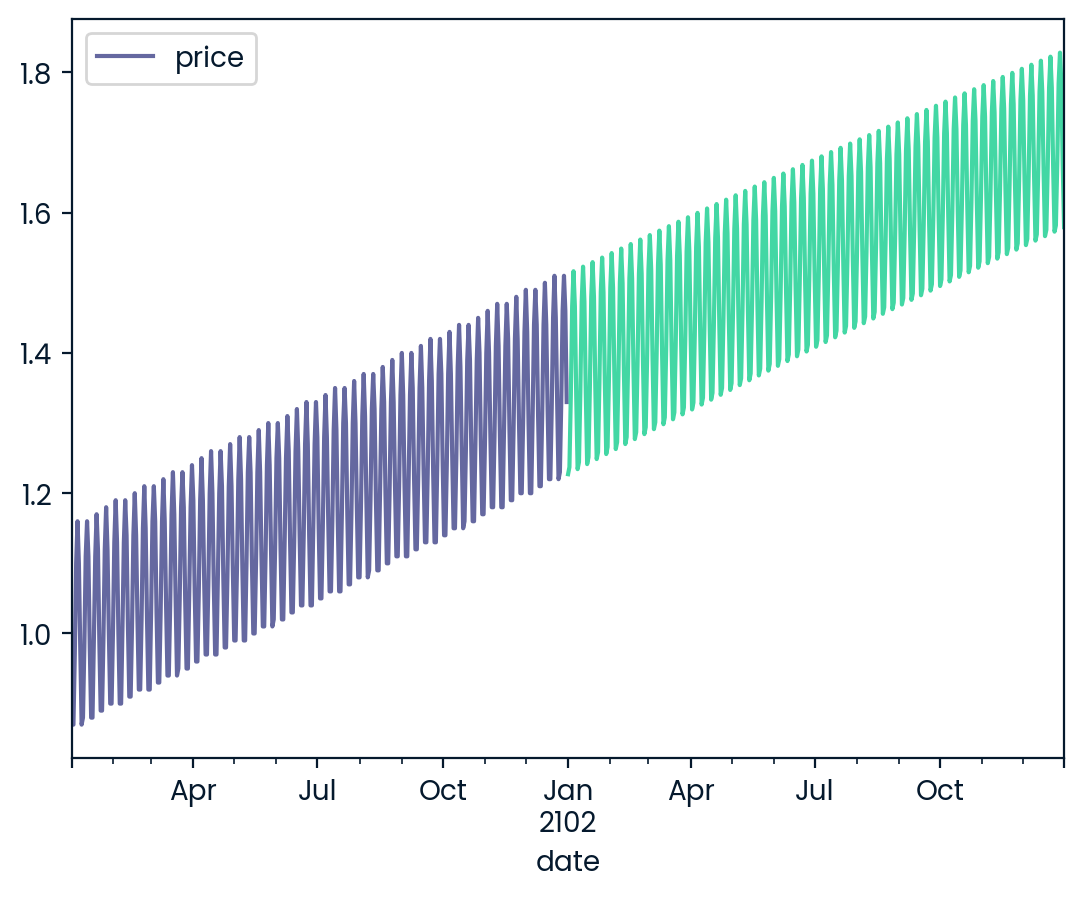

In [521]:
forecast = results.get_forecast(steps=365)
predicted = forecast.predicted_mean
predicted
fuel_prices.plot()
predicted.plot()

In [522]:
predicted_df = predicted.to_frame()
predicted_df['doy'] = predicted.index.dayofyear

In [523]:
team_flights['doy'] = team_flights['departure_datetime'].dt.dayofyear
team_flights.sort_values('departure_datetime')

,team_name,departure_datetime,landing_datetime,travel_distance_miles,doy
153,Elegant Eagles,2102-04-03 21:40:00,2102-04-03 23:19:59,833.194444,93
649,Rapid Rabbits,2102-04-03 21:40:00,2102-04-03 23:13:44,781.111111,93
725,Tough Tigers,2102-04-03 21:52:00,2102-04-03 23:17:13,710.138889,93
1031,Bumbling Beavers,2102-04-03 22:02:00,2102-04-03 23:27:39,713.750000,93
992,Angry Alpacas,2102-04-03 22:04:00,2102-04-03 23:32:21,736.250000,93
...,...,...,...,...,...
76,Brave Bears,2102-09-30 03:44:00,2102-09-30 05:25:10,843.055556,273
152,Daring Dragons,2102-09-30 04:03:00,2102-09-30 09:28:32,2712.777778,273
534,Noble Narwhals,2102-09-30 05:19:00,2102-09-30 07:12:27,945.416667,273
381,Jovial Jaguars,2102-09-30 06:38:00,2102-09-30 07:16:51,323.750000,273


In [524]:
merged_df = team_flights.merge(predicted_df, on='doy', how='left', validate='many_to_one')

In [525]:
merged_df['cost'] = merged_df['predicted_mean'] * merged_df['travel_distance_miles']
total_fuel_spend_2102_dollars = merged_df['cost'].sum()